In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [8]:
df = pd.read_csv('complete_data.csv')
df

,Unnamed: 0,customer_id,tenure_months,monthly_charge,support_tickets,contract,churned,data_issue
0,0,C101,24,3000.0,0,Annual,False,False
1,1,C102,3,6000.0,5,Monthly,True,False
2,2,C103,18,3000.0,1,Annual,False,False
3,3,C104,6,4500.0,4,Monthly,True,False
4,4,C105,36,6000.0,0,Annual,False,False
5,5,C106,12,4500.0,2,Monthly,False,False
6,6,C107,2,3000.0,6,Monthly,True,False
7,7,C108,8,NaN,3,Annual,True,True
8,8,C109,30,4500.0,1,Annual,False,False
9,9,C110,2,6000.0,7,Monthly,True,False


calculate the mean and median tenure with NumPy

In [9]:
tenure = df["tenure_months"].to_numpy()

mean_tenure = np.mean(tenure)
median_tenure = np.median(tenure)

print(F"Mean tenure: {mean_tenure:.2f} months")
print(F"Median tenure: {median_tenure:.2f} months")

Mean tenure: 14.18 months
Median tenure: 12.00 months


calculate the average support-ticket count for churned and non-churned customers

In [10]:
churned_tickets = df.loc[
    df["churned"] == True,
    "support_tickets"
].to_numpy()

retained_tickets = df.loc[
    df["churned"] == False,
    "support_tickets"
].to_numpy()

avg_churned_tickets = np.mean(churned_tickets)
avg_retained_tickets = np.mean(retained_tickets)

print(f"Churned customers: {avg_churned_tickets:.2f}")
print(f"Non-churned customers: {avg_retained_tickets:.2f}")

Churned customers: 5.00
Non-churned customers: 0.50


create a histogram of tenure

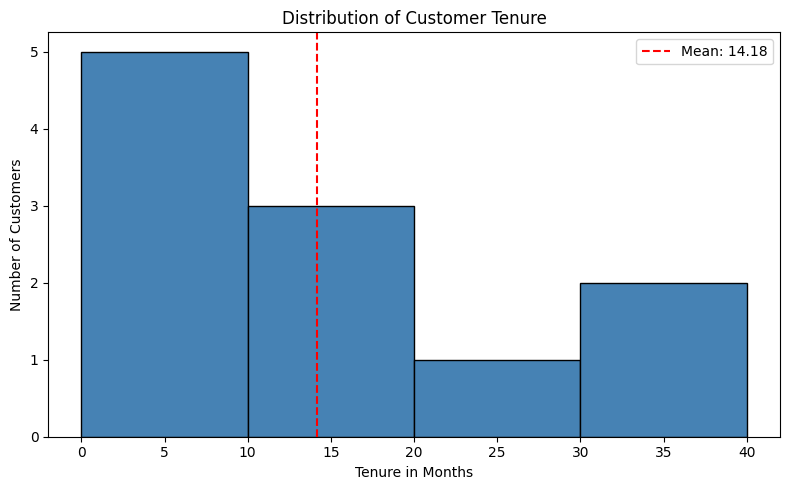

In [11]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["tenure_months"],
    bins=[0, 10, 20, 30, 40],
    color="steelblue",
    edgecolor="black"
)

plt.axvline(
    mean_tenure,
    color="red",
    linestyle="--",
    label=f"Mean: {mean_tenure:.2f}"
)

plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure in Months")
plt.ylabel("Number of Customers")
plt.legend()
plt.tight_layout()
plt.show()

create a bar chart comparing average support tickets by churn status

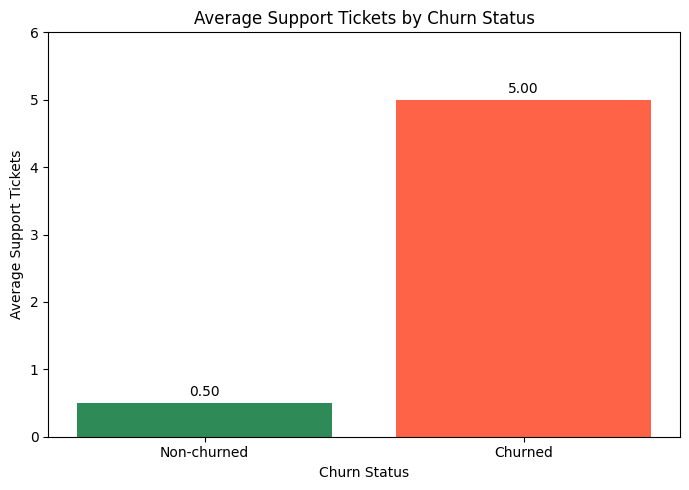

In [12]:
labels = ["Non-churned", "Churned"]
averages = [avg_retained_tickets, avg_churned_tickets]

plt.figure(figsize=(7, 5))

bars = plt.bar(
    labels,
    averages,
    color=["seagreen", "tomato"]
)

plt.title("Average Support Tickets by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Average Support Tickets")

for bar, value in zip(bars, averages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{value:.2f}",
        ha="center"
    )

plt.ylim(0, max(averages) + 1)
plt.tight_layout()
plt.show()